In [19]:
import matplotlib.pyplot as plt 
import numpy as np

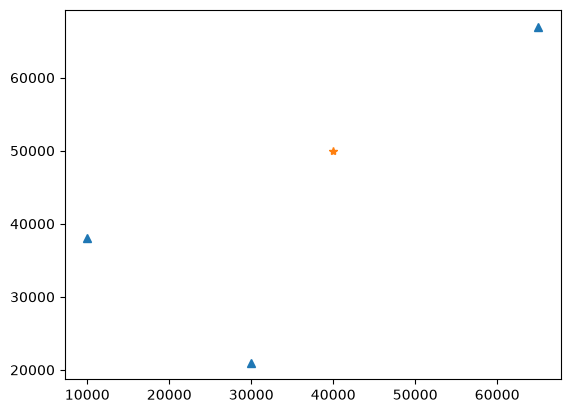

In [20]:
# Definimos a posição das estações e do epicentro
x_stations = np.array([10e3, 30e3, 65e3]) # m
y_stations = np.array([38e3, 21e3, 67e3]) # m 
# Alinhando as estações fazendo o problemas ser não unico (mal posto)
#x_stations = np.array([10e3, 35e3, 65e3]) # m
#y_stations = np.array([38e3, 55e3, 67e3]) # m 
x_true = 40e3
y_true = 50e3
# Definimos Vp e Vs
vp = 6700 # m/s
vs = 4400 # m/s
# Vamos plotar isso tudo
plt.plot(x_stations, y_stations, '^')
plt.plot(x_true, y_true, '*')

In [21]:
# Vamos calcular os nossos dados
#data = (1 / vs - 1 / vp) * np.sqrt((x_true - x_stations) ** 2 + (y_true - y_stations) ** 2)
# Podemos usar a função Hypot do numpy também
data = (1 / vs - 1 / vp) * np.hypot(x_true - x_stations, y_true - y_stations)
data *= np.random.default_rng().normal(0, 0.001 * np.abs(data).max(), data.size)

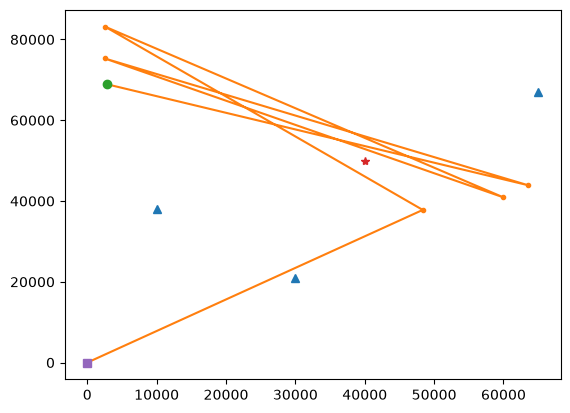

In [22]:
# Vamos criar nossa matriz jacobiana 
p_initial = np.array([0, 0]) # Chute inicial
steps = [p_initial]
p = p_initial
for i in range(6):
    G = np.empty((data.size, 2))
    G[:, 0] = (1 / vs - 1 / vp) * (p[0] - x_stations) / np.hypot(p[0] - x_stations, p[1] - y_stations)
    G[:, 1] = (1 / vs - 1 / vp) * (p[1] - y_stations) / np.hypot(p[0] - x_stations, p[1] - y_stations)
    predicted_data = (1 / vs - 1 / vp) * np.hypot(p[0] - x_stations, p[1] - y_stations)
    delta_p = np.linalg.solve(G.T @ G, G.T @ (data - predicted_data))
    p = p + delta_p
    steps.append(p)
steps = np.transpose(steps)
# Vamos plotar tudo e ver como fica
plt.plot(x_stations, y_stations, '^')
plt.plot(steps[0], steps[1], ".-")
plt.plot(p[0], p[1], 'o')
plt.plot(x_true, y_true, '*')
plt.plot(p_initial[0], p_initial[1], "s")

<function matplotlib.pyplot.show(close=None, block=None)>

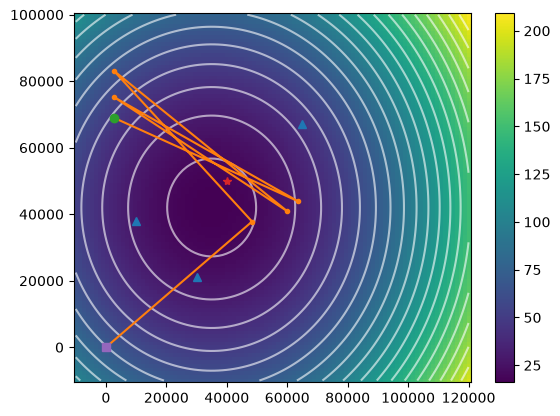

In [23]:
# Vamos calcular nossa função objetivo nessa áerea e observar seu comportamento
x = np.linspace(-10e3, 120e3, 100)
y = np.linspace(-10e3, 100e3, 100)
goal = np.empty((x.size, y.size))
for i in range(y.size):
        for j in range(x.size):
            predicted_data = (1 / vs - 1 / vp) * np.hypot(x[j] - x_stations, y[i] - y_stations)
            goal[i,j] = np.linalg.norm(data - predicted_data) ** 2 

plt.pcolormesh(x, y, goal)
plt.colorbar()
plt.contour(x, y, goal, levels=20, colors='white', alpha=0.6)
plt.plot(x_stations, y_stations, '^')
plt.plot(steps[0], steps[1], ".-")
plt.plot(p[0], p[1], 'o')
plt.plot(x_true, y_true, '*')
plt.plot(p_initial[0], p_initial[1], "s")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

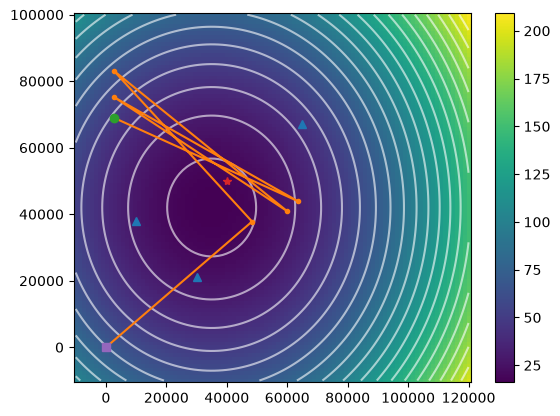

In [24]:
# Vamos testar diferentes chutes iniciais
p_initial = np.array([0, 0]) # Chute inicial
steps = [p_initial]
p = p_initial
for i in range(6):
    G = np.empty((data.size, 2))
    G[:, 0] = (1 / vs - 1 / vp) * (p[0] - x_stations) / np.hypot(p[0] - x_stations, p[1] - y_stations)
    G[:, 1] = (1 / vs - 1 / vp) * (p[1] - y_stations) / np.hypot(p[0] - x_stations, p[1] - y_stations)
    predicted_data = (1 / vs - 1 / vp) * np.hypot(p[0] - x_stations, p[1] - y_stations)
    delta_p = np.linalg.solve(G.T @ G, G.T @ (data - predicted_data))
    p = p + delta_p
    steps.append(p)
steps = np.transpose(steps)

plt.pcolormesh(x, y, goal)
plt.colorbar()
plt.contour(x, y, goal, levels=20, colors='white', alpha=0.6)
plt.plot(x_stations, y_stations, '^')
plt.plot(steps[0], steps[1], ".-")
plt.plot(p[0], p[1], 'o')
plt.plot(x_true, y_true, '*')
plt.plot(p_initial[0], p_initial[1], "s")
plt.show